# Data Cleaning
In this file, we're gonna focus on the cleaning of our dataset, by:
- Handling of missing values (NaN)
- Removal of identifiers (IDs and Dates)
- Correlation analysis (redundancy)
- Normalization/Scaling

### 1. Dataset

In [18]:
DATA_PATH = "../data/daily_injury_data.csv"

### 2. Imports

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score

### 3. Handling of missing values(NaN)

In sports, an empty space on a training usually doesn't mean that the data was lost, but rather that the athlete didn't make that effort.

Therefore, in this section we're gonna identify where the empty space makes sense being a zero (0). This dataset uses -0.01 to indicate the lack of data

**Action**: substitute -0.01 for 0.0. If there's collumns totally empties or with to many errors, remove them

In [20]:
# load the dataset
df = pd.read_csv(DATA_PATH)

# replace -0.01 for 0.0
df.replace(-0.01, 0.0, inplace=True)

print(f"Dataset loaded with {df.shape[0]} rows")
print(f"Number of negative values after cleaning: {(df < 0).sum().sum()}")

Dataset loaded with 42766 rows
Number of negative values after cleaning: 0


### 4. Removal of Identifiers (IDs and Dates)

In this section, the goal is to "don't addict the model". The objective of Machine Learning is generalization, so if there's a collumn named ID, the model can learn that, for example, "Everytime the ID 12 trains, he gets an injury", which is useless to predict injuries in a new athlete. We want the model to learn physical patterns, not IDs ("names").

**Action**: remove the columns Athlete ID and Date

In [21]:
# Save the IDS and Dates in separate variables (can be usefull later)
athlete_ids = df['Athlete ID']
dates = df['Date']

# Remove the columns 
df.drop(['Athlete ID', 'Date'], axis=1, inplace=True)

print("Columns removed")
print(f"Remaining columns: {len(df.columns)}")


Columns removed
Remaining columns: 71


### 5. Correlation Analysis (redundancy)

In your dataset we have some columns that say the exact same thing, which means that we have the information duplicated. By having this, the model gets confused and gives double importance to the same information.

**Action**: create a correlation matrix, and if two variables have a high correlation (near 1.0), we need to delet one

***Note***: in the correlation matrix we are only gonna select the base columns, i.e. since your dataset has the same columns for each day, we are only gonna choose the columns of today, so that we obtain a more simple and clear matrix with all the information that we need

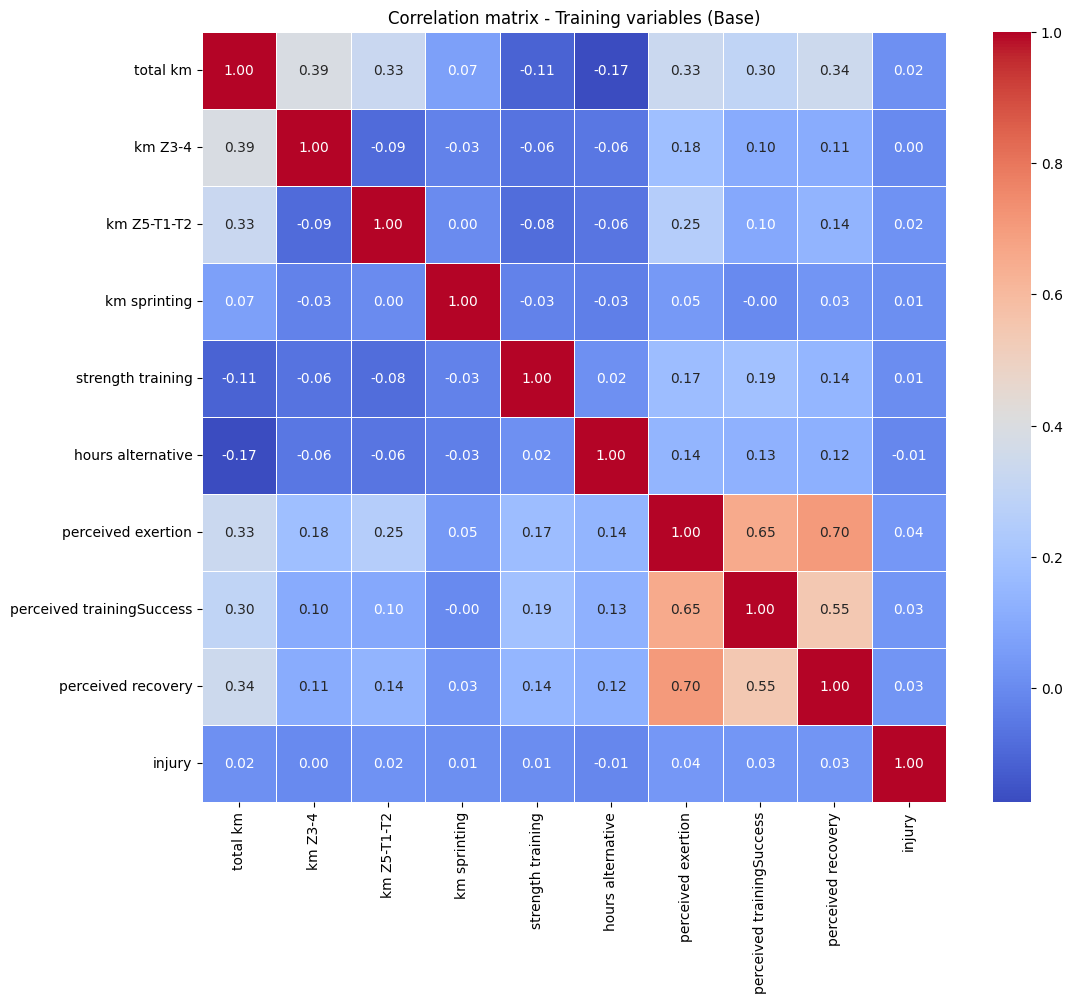

In [24]:
# select the base columns only
base_cols = []
for col in df.columns:
    if '.' not in col:
        base_cols.append(col)
corr_matrix = df[base_cols].corr()

# create the graphic
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation matrix - Training variables (Base)")
plt.show()

**Analysis of the correlation matrix**

Looking at the correlation matrix, there's no value equal or higher than 0.9, therefore we decided, for now, not to eliminate any colum.

The only variables that come close to this value are the *perceived exertion*, *perceived trainingSuccess* and *perceived recovery*, with values between 0.55 and 0.70. This shows that the athlets perception is consistent, when he feels that the training was hard, he also feels that the recovery was worse.

### 6. Normalization/Scaling

In our dataset we have values that have different scales, so some of them are higher than others, and that can confuse the model, leading him to think that the higher values are more import than the lowest ones. Therefore, we are gonna use the **Min-Max Scaling** tecnic, to normalize all the values

**Action**: transform all the values to a scale between 0 and 1

In [28]:
scaler = MinMaxScaler()

# separte column "injury" because it's already 0 or 1
target = df['injury']
features = df.drop('injury', axis=1)

# apply normalization (it will return a simple list)
features_scaled = scaler.fit_transform(features)

# transform back into a dataframe
df_final = pd.DataFrame(features_scaled, columns=features.columns)

# add column 'injury' 
df_final['injury'] = target.values

print("Normalization completed!")
df_final.head()

Normalization completed!


,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,...,total km.6,km Z3-4.6,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6,injury
0,0.5,0.103757,0.0,0.0125,0.03,0.0,0.000000,0.11,0.0,0.18,...,0.000000,0.000000,0.000000,0.00,0.0,0.05,0.10,0.0,0.15,0
1,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.00,0.0,0.00,...,0.093023,0.000000,0.010417,0.03,0.0,0.00,0.10,0.0,0.17,0
2,0.5,0.000000,0.0,0.0000,0.00,0.5,0.000000,0.10,0.0,0.17,...,0.000000,0.000000,0.000000,0.00,0.0,0.00,0.00,0.0,0.00,0
3,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.00,0.0,0.00,...,0.000000,0.000000,0.000000,0.00,0.5,0.00,0.10,0.0,0.17,0
4,0.5,0.000000,0.0,0.0000,0.00,0.0,0.105675,0.08,0.0,0.18,...,0.314848,0.170616,0.000000,0.00,0.0,0.00,0.11,0.0,0.17,0


### 7. Export new dataset

In [37]:
df_final.to_csv("../data/daily_injury_data_clean.csv", index=False)
print("Saved:", "daily_injury_data_clean.csv", "| Shape:", df_final.shape)

Saved: daily_injury_data_clean.csv | Shape: (42766, 71)
